# Python front end: parameter scans and ion phase space

## Pablo Requeijo

This notebook drives the hybrid PIC directly from Python through the `pic_prequeijo` module (pybind11, `python/bindings.cpp`). It runs exactly the same C++ code as the `pic_prequeijo` driver (the pytest suite checks they agree bit for bit), but two kinds of analysis become easy that the driver makes tedious:

1. **Parameter scans**: dozens of runs with different settings, without writing one `.txt` input file per run.
2. **Particle data**: the driver only saves grid moments, while `HybridSimulation.particles()` returns every macroparticle's position and velocity at any time.

## Setup

Build the project first (from `PIC/build`, configured with the repo venv): `cmake .. -DPython_EXECUTABLE=../../.venv/bin/python && cmake --build .`. This notebook needs no `results.h5`: every run happens here.

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt

# Shared notebook helpers (python/) and the pybind11 module (build/).
sys.path[:0] = ["python", "build"]
import pic_analysis as pa
import pic_prequeijo as pic

pa.apply_style()

## 1. Dispersion relation from a wavenumber scan

`analysis_session_3.ipynb` checks one R and one L eigenmode at $k d_i = 1$, and sees the whole dispersion relation only through thermal noise. Here each eigenmode is run separately, for 12 wavenumbers on each branch, and its frequency is measured from the phase of its Fourier mode (`pa.mode_frequency`). The analytic reference is the cold-plasma relation $\omega^2 + k^2\omega - k^2 = 0$ (`pic.wave_frequency`).

Setup: cold protons in $\vec B_0 = \hat x$, box $L = 8\pi\,d_i$, so mode $m$ has $k = m/4$ and $m = 1 \dots 12$ spans $k d_i = 0.25 \dots 3$. Each run lasts 3 wave periods, and the wave amplitude $10^{-3}$ keeps it linear. $dt = 0.005$ is below the whistler stability limit $n\,dx^2/2 = 0.019$ for $n_x = 128$.

In [2]:
BOX_LENGTH = 8 * np.pi
WAVE_AMPLITUDE = 1e-3
PERIODS_PER_RUN = 3
SCAN_MODES = np.arange(1, 13)
BRANCHES = ("L", "R")


def measure_eigenmode(branch, mode, nx, dt):
    # Runs one cold eigenmode for PERIODS_PER_RUN periods and returns its
    # wavenumber and the relative error of its measured frequency.
    k = 2 * np.pi * mode / BOX_LENGTH
    exact = pic.wave_frequency(k, branch)
    steps = int(np.ceil(PERIODS_PER_RUN * 2 * np.pi / abs(exact) / dt))
    sim = pic.HybridSimulation(nx=nx, length=BOX_LENGTH, dt=dt, B=(1, 0, 0), ppc=4,
                               wave_mode=int(mode), wave_amplitude=WAVE_AMPLITUDE,
                               wave_branch=branch, output_every=5)
    sim.run(steps)
    omega, _ = pa.mode_frequency(sim.history(), k)
    return k, omega, (omega - exact) / exact


SCAN_NX, SCAN_DT = 128, 0.005
scan = {branch: np.array([measure_eigenmode(branch, mode, SCAN_NX, SCAN_DT)
                          for mode in SCAN_MODES])
        for branch in BRANCHES}
for branch in BRANCHES:
    k, omega, error = scan[branch].T
    print(f"{branch} branch: |relative error| from {np.abs(error).min():.1e} "
          f"(k = {k[np.abs(error).argmin()]:.2f}) to {np.abs(error).max():.1e} "
          f"(k = {k[np.abs(error).argmax()]:.2f})")

L branch: |relative error| from 7.4e-04 (k = 0.25) to 3.1e-03 (k = 3.00)
R branch: |relative error| from 9.3e-04 (k = 0.25) to 3.2e-02 (k = 3.00)


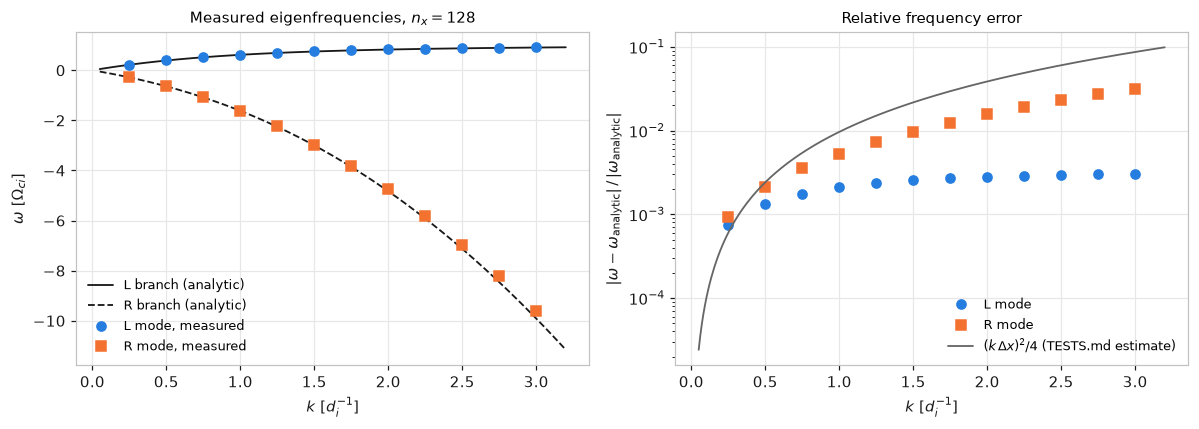

R mode at k = 3.00: error -3.17e-02 vs omega(k), -5.65e-03 vs omega(k_eff)


In [3]:
dx = BOX_LENGTH / SCAN_NX
k_dense = np.linspace(0.05, 3.2, 300)
markers = {"L": "o", "R": "s"}
colors = {"L": pa.L_BRANCH_COLOR, "R": pa.R_BRANCH_COLOR}

fig, (ax_w, ax_err) = plt.subplots(1, 2, figsize=(11, 4))
pa.plot_wave_branches(ax_w, k_dense)
for branch in BRANCHES:
    k, omega, error = scan[branch].T
    ax_w.plot(k, omega, markers[branch], color=colors[branch], ms=6,
              label=f"{branch} mode, measured")
    ax_err.plot(k, np.abs(error), markers[branch], color=colors[branch], ms=6,
                label=f"{branch} mode")
ax_err.plot(k_dense, (k_dense * dx)**2 / 4, color=pa.ANALYTIC_COLOR, lw=1.2,
            label=r"$(k\,\Delta x)^2/4$ (TESTS.md estimate)")
ax_w.set(xlabel=r"$k\ [d_i^{-1}]$", ylabel=r"$\omega\ [\Omega_{ci}]$",
         title=r"Measured eigenfrequencies, $n_x = 128$")
ax_err.set(xlabel=r"$k\ [d_i^{-1}]$", ylabel=r"$|\omega - \omega_{\rm analytic}|\,/\,|\omega_{\rm analytic}|$",
           yscale="log", title="Relative frequency error")
ax_w.legend()
ax_err.legend()
plt.tight_layout()
plt.show()

# Grid dispersion: the two centered derivatives of curl(curl B) see
# k_eff = (2/dx) sin(k dx/2) instead of k.
k, omega, error = scan["R"].T
k_eff = 2 / dx * np.sin(k * dx / 2)
error_eff = (omega - pic.wave_frequency(k_eff, "R")) / pic.wave_frequency(k_eff, "R")
print(f"R mode at k = {k[-1]:.2f}: error {error[-1]:+.2e} vs omega(k), "
      f"{error_eff[-1]:+.2e} vs omega(k_eff)")

Both branches follow the analytic relation, from the Alfvénic regime ($|\omega| \approx k$ at small $k$) to the ion-cyclotron saturation of L ($\omega \to \Omega_{ci}$) and the quadratic whistler growth of R. The error grows with $k$ on the R branch, up to 3 % at $k d_i = 3$ ($k\,\Delta x = 0.59$, about 11 cells per wavelength). Most of it is the grid dispersion of the centered differences, which see $k_{\rm eff} = (2/\Delta x)\sin(k\,\Delta x/2) < k$: measured against $\omega(k_{\rm eff})$, the same run is off by only 0.6 %. The L branch saturates near $\Omega_{ci}$, where $\omega$ barely depends on $k$, so the same grid error barely moves it.

The error stays below the estimate $(k\,\Delta x)^2/4$ of `TESTS.md` except at the smallest wavenumber, $k d_i = 0.25$, where it is $7$–$9\times10^{-4}$ on both branches while the estimate gives $6\times10^{-4}$. To see whether that excess is numerical or physical, the next cell repeats three wavenumbers at three resolutions.

### Convergence with the cell size

If the error comes from the spatial discretization, halving $\Delta x$ must divide it by 4 (second-order Yee derivatives and linear shape function). The time step is fixed at $dt = 0.0025$, stable for the finest mesh ($n_x = 256$, limit $0.0048$), and small enough that the second-order time error stays below the spatial one.

L, k = 0.25: error ratios when dx halves: 4.00, 3.99
L, k = 1: error ratios when dx halves: 3.98, 3.99
L, k = 3: error ratios when dx halves: 3.85, 3.98
R, k = 0.25: error ratios when dx halves: 4.00, 4.01
R, k = 1: error ratios when dx halves: 3.97, 3.99
R, k = 3: error ratios when dx halves: 3.83, 3.94


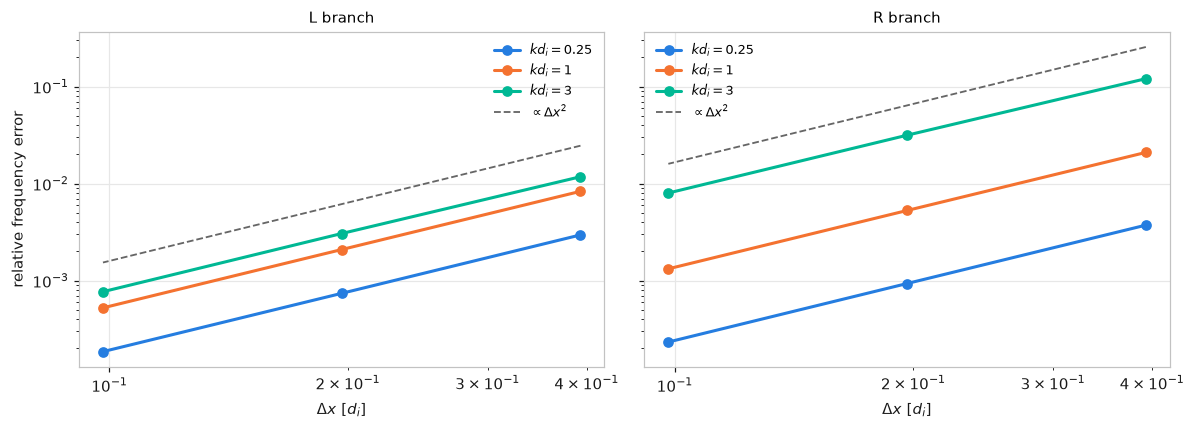

In [4]:
CONVERGENCE_NX = np.array([64, 128, 256])
CONVERGENCE_MODES = (1, 4, 12)
CONVERGENCE_DT = 0.0025

convergence = {(branch, mode): np.array([measure_eigenmode(branch, mode, nx, CONVERGENCE_DT)[2]
                                         for nx in CONVERGENCE_NX])
               for branch in BRANCHES for mode in CONVERGENCE_MODES}

dx_values = BOX_LENGTH / CONVERGENCE_NX
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, branch in zip(axes, BRANCHES):
    for slot, mode in enumerate(CONVERGENCE_MODES):
        error = np.abs(convergence[(branch, mode)])
        ax.plot(dx_values, error, "o-", color=pa.SERIES_COLORS[slot],
                label=rf"$k d_i = {mode / 4:g}$")
        ratios = error[1:] / error[:-1]
        print(f"{branch}, k = {mode / 4:g}: error ratios when dx halves: "
              + ", ".join(f"{1 / r:.2f}" for r in ratios))
    # Slope-2 reference, shifted above the largest error so it does not hide it.
    top = max(np.abs(convergence[(branch, mode)])[-1] for mode in CONVERGENCE_MODES)
    ax.plot(dx_values, 2 * top * (dx_values / dx_values[-1])**2, color=pa.ANALYTIC_COLOR,
            lw=1.2, ls="--", label=r"$\propto \Delta x^2$")
    ax.set(xscale="log", yscale="log", xlabel=r"$\Delta x\ [d_i]$",
           title=f"{branch} branch")
    ax.legend()
axes[0].set_ylabel("relative frequency error")
plt.tight_layout()
plt.show()

Every curve is parallel to $\Delta x^2$: the error drops by a factor of 4 each time $\Delta x$ halves (printed ratios 3.8 to 4.0), at all three wavenumbers, including the smallest. The excess at $k d_i = 0.25$ is therefore spatial truncation, not physics or measurement. Its coefficient is larger than the $(k\,\Delta x)^2/4$ estimate, so at small $k$ there is a second-order spatial error that does not scale as $k^2$. Its origin is not identified in this notebook. It converges at the same rate, and it is below the tolerance of the `[hybrid]` eigenmode tests at $k d_i = 1$.

## 2. Ion phase space in an ion acoustic wave

The driver saves only the grid moments $n$ and $\vec u$; here the macroparticles themselves are inspected. Setup as `examples/density_sine.txt`, but with the initial density passed as a NumPy array instead of a profile file: cold protons, $T_e = 1$, $L = 20\pi$, $n(x, 0) = 1 + \varepsilon\cos kx$ with $\varepsilon = 0.01$ and $k = 2\pi/L = 0.1$.

**Linear solution.** The density bump launches a standing ion acoustic wave, $n = 1 + \varepsilon\cos kx\cos\omega t$ with $\omega = k\sqrt{T_e}$. Continuity, $\partial_t n + \partial_x(n u_x) = 0$, gives to first order in $\varepsilon$

$$u_x(x, t) = \varepsilon\sqrt{T_e}\,\sin kx\,\sin\omega t.$$

The ions are cold, so each one should move with the local bulk velocity: in the $(x, v_x)$ plane they must lie on this curve. Its amplitude is $\varepsilon\sqrt{T_e} = 0.01$, reached at $t = T/4$ and $3T/4$; at $t = T/2$ the ions are momentarily at rest.

t =  15.70 (T/4): max |v_x - u_x| = 8.49e-05 = 0.8% of the amplitude, max |v_y|, |v_z| = 0.0e+00
t =  31.40 (T/2): max |v_x - u_x| = 1.82e-04 = 1.8% of the amplitude, max |v_y|, |v_z| = 0.0e+00


t =  47.10 (3T/4): max |v_x - u_x| = 2.50e-04 = 2.5% of the amplitude, max |v_y|, |v_z| = 0.0e+00


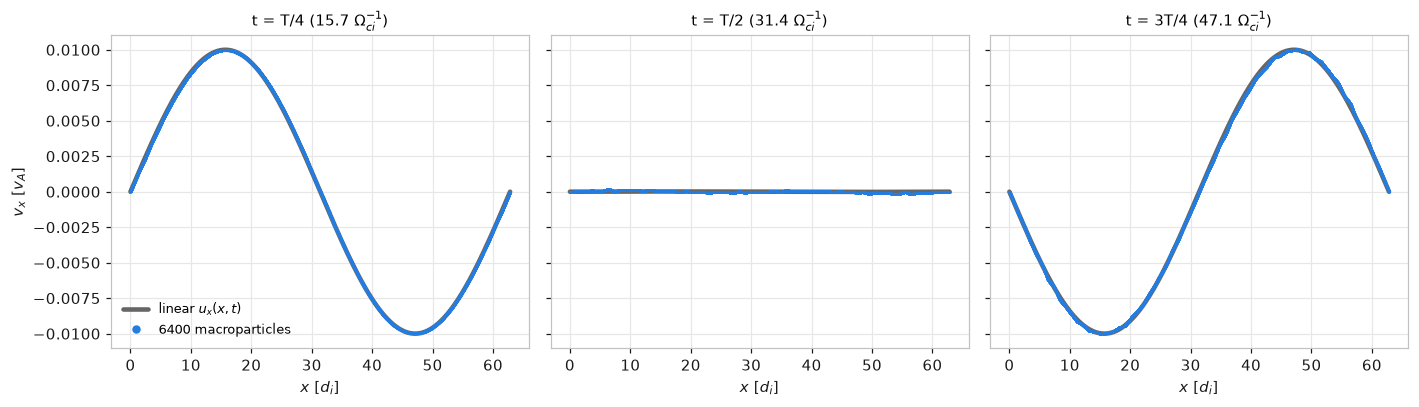

In [5]:
DENSITY_EPSILON = 0.01
ELECTRON_TEMPERATURE = 1.0
ACOUSTIC_NX, ACOUSTIC_LENGTH, ACOUSTIC_DT = 64, 20 * np.pi, 0.05

k = 2 * np.pi / ACOUSTIC_LENGTH
x_nodes = np.arange(ACOUSTIC_NX) * ACOUSTIC_LENGTH / ACOUSTIC_NX
sim = pic.HybridSimulation(nx=ACOUSTIC_NX, length=ACOUSTIC_LENGTH, dt=ACOUSTIC_DT,
                           B=(1, 0, 0), Te=ELECTRON_TEMPERATURE, ppc=100,
                           density=1 + DENSITY_EPSILON * np.cos(k * x_nodes))
omega = k * np.sqrt(ELECTRON_TEMPERATURE)
period = 2 * np.pi / omega
u_amplitude = DENSITY_EPSILON * np.sqrt(ELECTRON_TEMPERATURE)
x_dense = np.linspace(0, ACOUSTIC_LENGTH, 400)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, fraction, name in zip(axes, (0.25, 0.5, 0.75), ("T/4", "T/2", "3T/4")):
    sim.run(int(round(fraction * period / ACOUSTIC_DT)) - sim.step)
    particles = sim.particles()
    vx = particles["v"][:, 0]
    u_particles = u_amplitude * np.sin(k * particles["x"]) * np.sin(omega * sim.time)
    deviation = np.abs(vx - u_particles).max()
    print(f"t = {sim.time:6.2f} ({name}): max |v_x - u_x| = {deviation:.2e} "
          f"= {deviation / u_amplitude:.1%} of the amplitude, "
          f"max |v_y|, |v_z| = {np.abs(particles['v'][:, 1:]).max():.1e}")
    ax.plot(x_dense, u_amplitude * np.sin(k * x_dense) * np.sin(omega * sim.time),
            color=pa.ANALYTIC_COLOR, lw=3, label=r"linear $u_x(x, t)$")
    ax.plot(particles["x"], vx, ".", ms=1.5, color=pa.SERIES_COLORS[0],
            label=f"{len(vx)} macroparticles")
    ax.set(xlabel=r"$x\ [d_i]$", title=f"t = {name} ({sim.time:.1f} $\\Omega_{{ci}}^{{-1}}$)")
axes[0].set_ylabel(r"$v_x\ [v_A]$")
axes[0].legend(loc="lower left", markerscale=6)
plt.tight_layout()
plt.show()

The macroparticles collapse onto the linear solution: a cold population is a single curve in phase space, and that curve oscillates as the standing wave, sloshing ions towards the density troughs and back. The largest deviation grows from 0.8 % to 2.5 % of the wave amplitude over three quarters of a period. That is of the same order as the terms the linear solution neglects (relative order $\varepsilon = 1\,\%$) and as the slow phase drift of the measured frequency ($\omega = 0.0999$ against $0.1$, see `README.md`); this notebook does not separate the two. $v_y$ and $v_z$ stay exactly zero, since in this longitudinal wave along $\vec B_0$ nothing pushes the ions across the field.